# VAMP and TCCA
Compare the performance of VAMP and other method to approximating the Koopman operator

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy  as sp

# from scipy.linalg import fractional_matrix_power
# import sys
# sys.path.append('./utils')

# import h5py
import importlib
# import analysis
# import datasets as ds
import seaborn as sns

# %matplotlib ipympl
# %matplotlib inline
from deeptime.decomposition import VAMP, EDMD, DMD, KernelCCA, KernelEDMD
from deeptime.clustering import KMeans
from deeptime.decomposition import vamp_score_cv
import fastplotlib as fpl

%matplotlib inline

wgpu version from git (0.15.3) and __version__ (0.19.3) don't match.
rendercanvas version from git (2.0.0) and __version__ (2.0.1) don't match.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅,AMD Radeon 780M (RADV GFX1103_R1),IntegratedGPU,Vulkan,Mesa 24.2.8
✅ (default),NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
✅,NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
❗ limited,"llvmpipe (LLVM 19.1.0, 256 bits)",CPU,Vulkan,Mesa 24.2.8 (LLVM 19.1.0)
❌,"AMD Radeon 780M (radeonsi, gfx1103_r1, LLVM 19.1.0, DRM 3.59, 6.12.4-200.fc41.x86_64)",Unknown,OpenGL,4.6 (Core Profile) Mesa 24.2.8


pygfx version from git (0.6.0) and __version__ (0.7.0) don't match.
Incompatible version of wgpu:
    Detected 0.15.3.post104+g63d70c0, need >=(0, 19, 0), <(0, 20, 0).
    To update, use e.g. `pip install -U wgpu`.


In [2]:
fpl.select_adapter(fpl.enumerate_adapters()[0])

In [3]:
def generate_data(
        n_timepoints: int,
        n_components: int,
        noise: int,
        n_pixels: int | tuple[int, int],  # n_pixels PER component, if a tuple a random number of pixles within the range is used
        n_pixels_bg = 0,
        firing_prop = 0.05,
        interp_factor: int = 2,
) -> tuple[np.ndarray, np.ndarray]:
    """

    Parameters
    ----------
    n_timepoints: int

    n_components: int

    noise: int

    n_pixels: int, or (min, max) range
        n_pixels PER components, if (min, max) range is given then a random number of pixels within this range
        is used for each component

    n_pixels_bg: int

    interp_factor: int
        interpolation factor

    Returns
    -------
    np.ndarray, np.ndarray
        data [pixels, n_timepoints * interp_factor], truth labels: 1D array 0 is background

    """

    clean = np.zeros((n_components, n_timepoints * interp_factor)) + 0.01
    print(clean)

    x = 0
    a_decay = 0.7
    a_rise = 5

    (0.01 / 5) * (5 / 0.01) * 5

    b = 0

    n_rise = 0

    spikes = list()

    for i in range(n_components):
        spikes.append((np.random.rand(n_timepoints) < firing_prop).astype(bool))

    for c_ix in range(n_components):
        for i in range(2, n_timepoints):
            if spikes[c_ix][i]:
                a = a_rise
                n_rise = 5
            elif n_rise > 0:
                if clean[c_ix, i - 1] > 1:
                    a = a_decay
                    n_rise = 0
                else:
                    a = a_rise
                    n_rise -= 1
            else:
                a = a_decay
            clean[c_ix, i] = (a * clean[c_ix, i - 1]) + (b * clean[c_ix, i - 2])# + (1 * spikes[c_ix][i])

        x_ = np.arange(0, n_timepoints * interp_factor)
        xp_ = np.linspace(0, n_timepoints * interp_factor, n_timepoints)
        clean[c_ix] = np.interp(x_, xp_, fp=clean[c_ix, :n_timepoints])

    n_timepoints *= interp_factor

    series = list()
    labels = list()

    for i in range(n_components):
        # determine number of pixels for this component
        if isinstance(n_pixels, int):
            _n_pixels_iter = n_pixels
        elif isinstance(n_pixels, tuple):
            _n_pixels_iter = np.random.randint(low=n_pixels[0], high=n_pixels[1])

        for j in range(_n_pixels_iter):
            series.append(clean[i] + np.random.normal(scale=noise, size=n_timepoints))
            labels.append(i + 1)

    # series = np.vstack(series)

    bg_pixels = [np.random.normal(scale=noise, size=n_timepoints) for i in range(n_pixels_bg)]
    series = np.vstack([*series, *bg_pixels])
    labels = np.array([*labels, *[0 for i in range(len(bg_pixels))]])

    return series, labels

In [4]:
np.random.seed(0)
X, _ = generate_data(
    n_timepoints=250,
    n_components=1,
    noise=0.2,
    n_pixels=1,
    n_pixels_bg=0,
    interp_factor=2,
    firing_prop=0.05,
)

[[0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01
  0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01
  0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01
  0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01
  0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01
  0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01
  0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01
  0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01
  0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01
  0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01
  0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01
  0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01
  0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01
  0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.01 0.

In [5]:
X.shape

(1, 500)

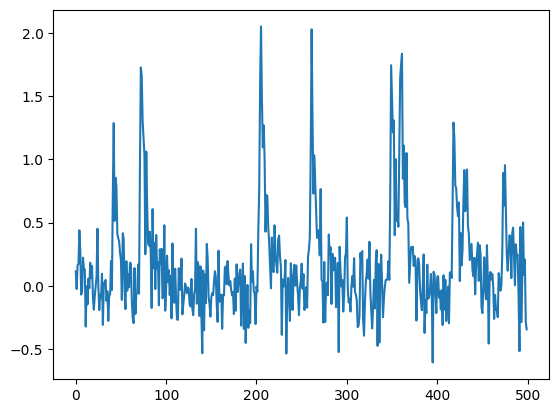

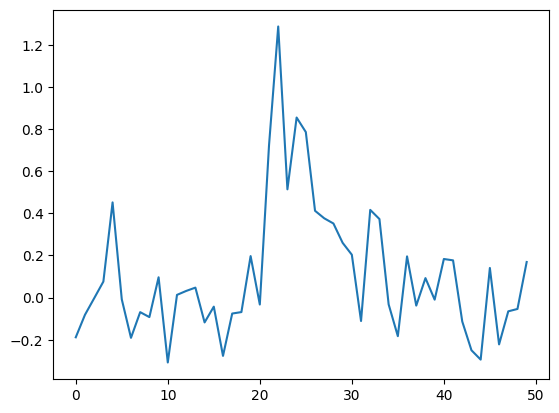

In [6]:
plt.plot(X[0])
# plt.plot(X[1])
plt.show()
plt.plot(X.ravel()[20:70])

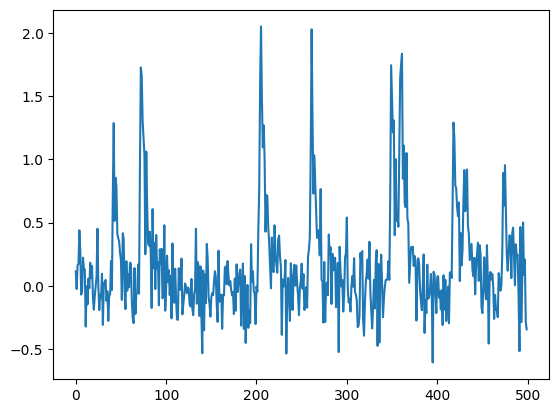

In [7]:
# tanh transient
traj = X.ravel()[:750]
# plt.plot(traj[:1000])
# add noise to the trajectory
# noise_std = 0.04
# traj_noise = traj + noise_std * np.random.randn(traj.size)
traj_noise = traj
plt.figure()
plt.plot(traj_noise)

In [8]:
# define the function to perform VAMP decomposition
from deeptime.basis import Monomials, Identity
def vamp_estimator(dim, lagtime, basis=Identity()):
    vamp_model =  VAMP(dim=dim,  # projection dimension
                       lagtime=lagtime,  # lag time
    observable_transform=basis,  # kernel embedding
    )
    return vamp_model

### Lag vector

In [9]:
traj_noise.shape

(500,)

In [10]:
# prepare the lag vectors
lag = 2
H = sp.linalg.hankel(traj_noise[:lag], traj_noise[lag-1:])
num_sample = H.shape[1]//lag - 1

<Axes: >

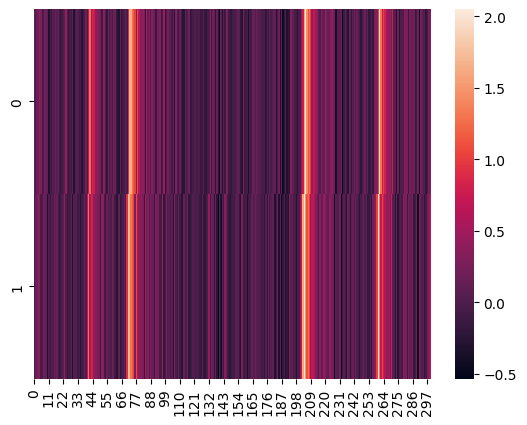

In [11]:
sns.heatmap(H[:, :300])

In [12]:
# make sure there is no overlap between past and future
H_past = H[:,0:num_sample*lag:lag]
H_future = H[:,lag:(num_sample*lag+lag):lag]
# make sure H_past and H_future have the same shape
assert H_past.shape == H_future.shape

<Axes: >

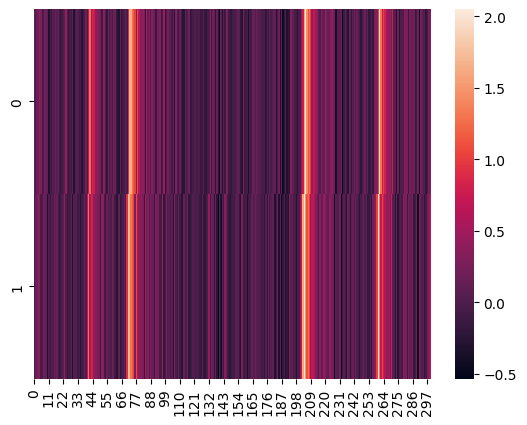

In [13]:
sns.heatmap(H[:, :300])

In [14]:
vamp_est = vamp_estimator(dim=3, lagtime=1)
vamp_model = vamp_est.fit(H_past.T).fetch_model()

# estimate the VAMP score
# scores = vamp_score_cv(vamp_est.fit(H_past.T), H.T, blocksize=100, random_state=42)
# print the average Vamp score
# print(f"Average Vamp score: {scores.mean()}")

# transform the data
projection = vamp_model.transform(H_past.T)
# print(f"Projection shape: {projection.shape}\n")

<Axes: >

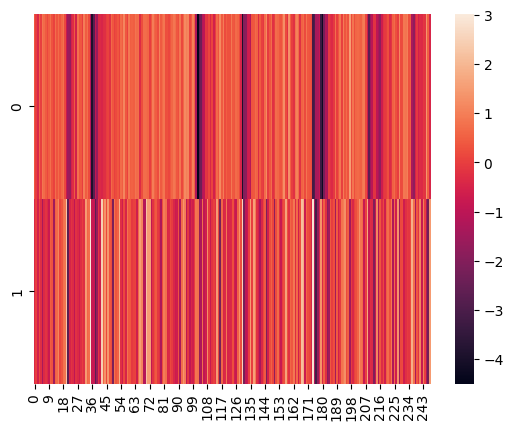

In [15]:
sns.heatmap(projection[:300].T)

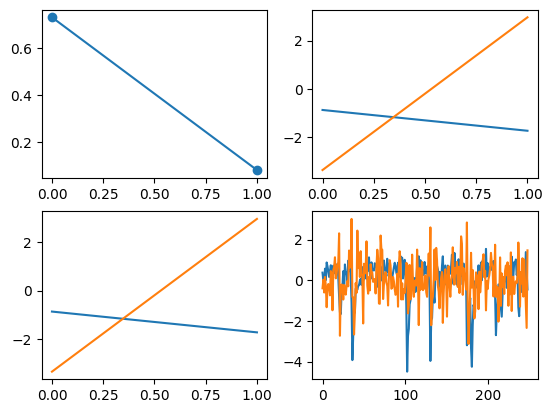

In [16]:
# make 2 by 2 plots, the first one is singular values, the second one is the first left singular vector
# the thrid one is the projection and the 4th one is the 3D scatter of the projection

fig, ax = plt.subplots(2,2)
ax[0,0].plot(vamp_model.singular_values[:],'o-')
ax[0,1].plot(vamp_model.singular_vectors_left[:,:3])
ax[1,0].plot(vamp_model.singular_vectors_left[:,:3])
ax[1,1].plot(projection)

### Nominals as basis function

We use the following momonial basis function up to order $M$,
$$\{1, x_1^px_2^q\cdot x_n^l\}, \quad p + q + \cdots + l \le M$$
for a given input vector $\vec{x}$

In [17]:
# we will use short lag vectors, so we will first subsample the input
# sub_sample = 5
traj_sub = traj_noise

# plt.plot(traj_sub[:50])
lag = 2
H = sp.linalg.hankel(traj_sub[:lag], traj_sub[lag-1:])

<Axes: >

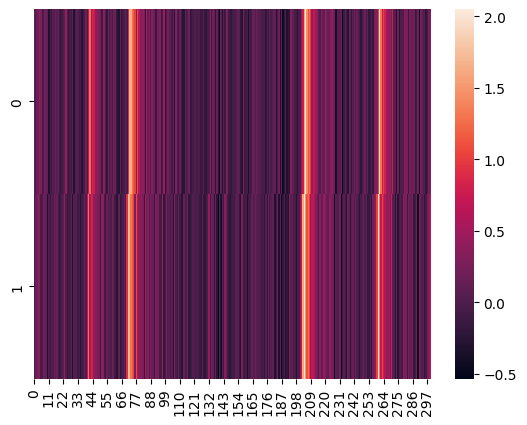

In [18]:
fig,ax = plt.subplots()
sns.heatmap(H[:, :300])

<Axes: >

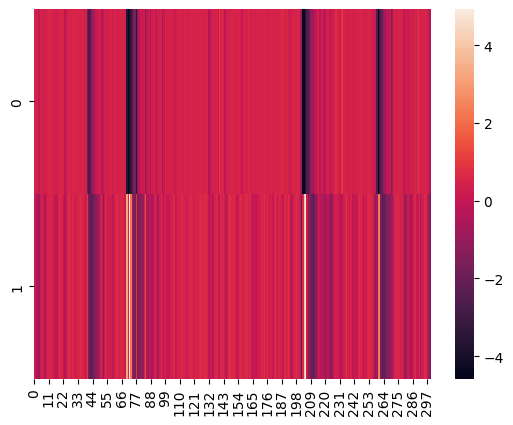

In [29]:
degree = lag
higher_order = 4
basis = Monomials(p=higher_order, d=degree)
vamp_est = vamp_estimator(dim=2, lagtime=2, basis=basis)
vamp_model = vamp_est.fit(H.T).fetch_model()

# estimate the VAMP score
# scores = vamp_score_cv(vamp_est.fit(H.T), H.T, blocksize=100, random_state=42)
# print the average Vamp score
# print(f"Average Vamp score: {scores.mean()}")

# transform the data
projection = vamp_model.transform(H.T).real
sns.heatmap(projection[:300].T)
# print(f"Projection shape: {projection.shape}\n")

<Axes: >

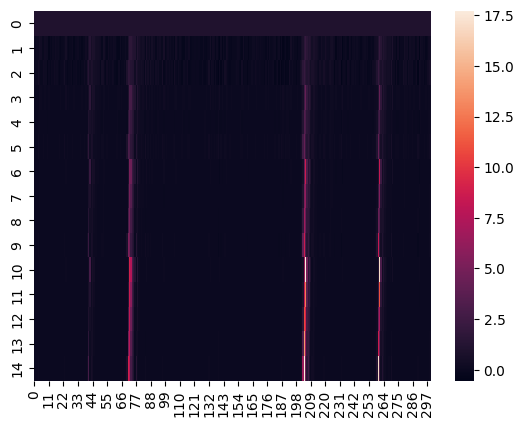

In [30]:
data_poly = vamp_est.observable_transform.transform(H.T)
sns.heatmap(data_poly.T[:, :300])

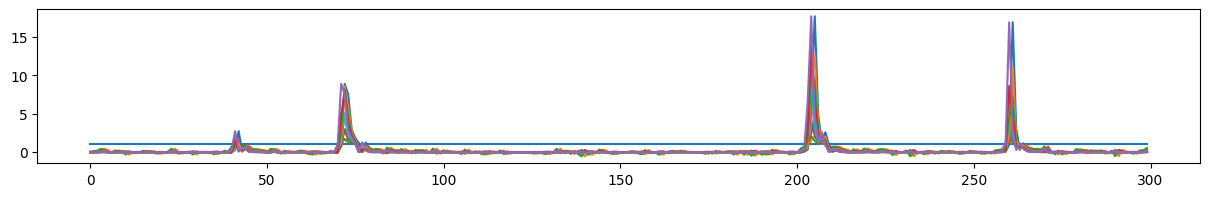

In [31]:
fig = plt.figure(figsize=(15, 2))
plt.plot(data_poly.T[:, :300].T)

In [32]:
data_poly.shape

(499, 15)

In [33]:
projection_right = data_poly @ vamp_model.singular_vectors_right

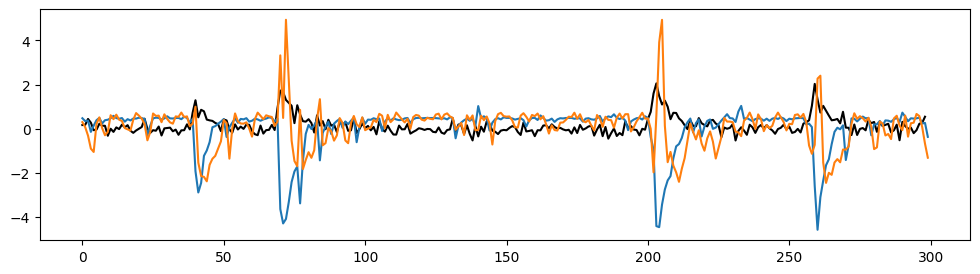

In [34]:
fig = plt.figure(figsize=(12, 3))
plt.plot(X.ravel()[lag:301], c="k")
plt.plot(projection[:300])

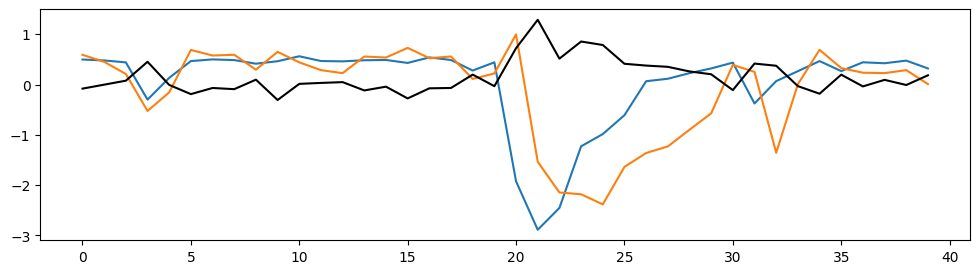

In [35]:
fig = plt.figure(figsize=(12, 3))
plt.plot(projection[20:60])
plt.plot(traj_noise[21:61], c="k")

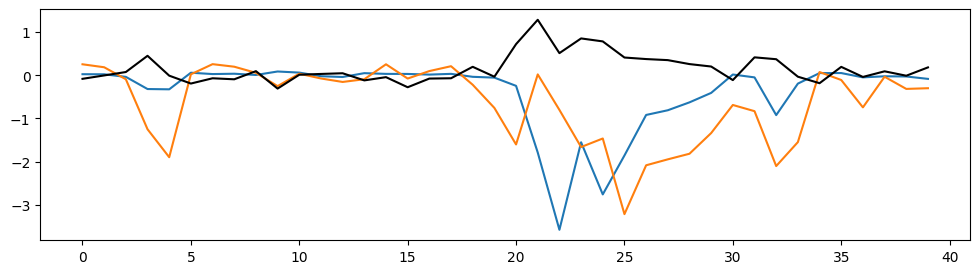

In [36]:
fig = plt.figure(figsize=(12, 3))
plt.plot(projection_right[20:60])
plt.plot(traj_noise[21:61], c="k")

(-15.0, 15.0)

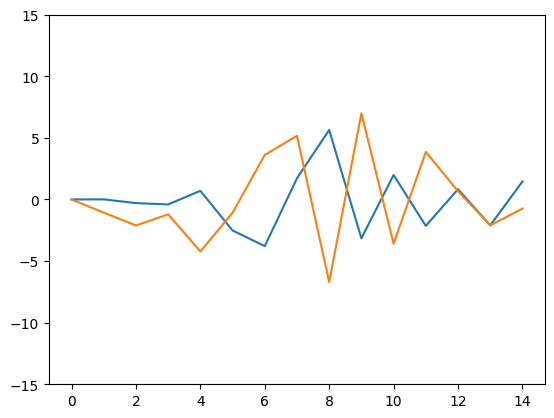

In [39]:
plt.plot(vamp_model.singular_vectors_left)
plt.ylim([-15, 15])

(-30.0, 30.0)

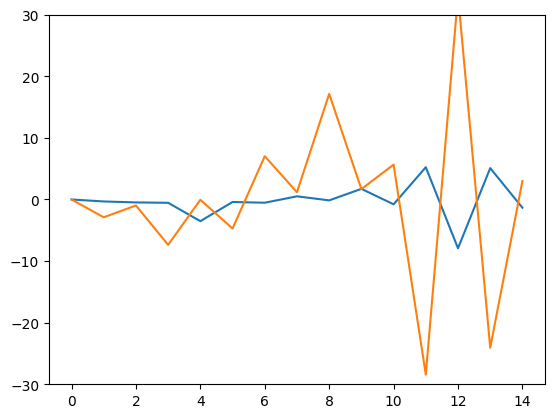

In [40]:
plt.plot(vamp_model.singular_vectors_right)
plt.ylim([-30, 30])

Text(0.5, 0.98, 'moniomial basis, order3, higher order 2')

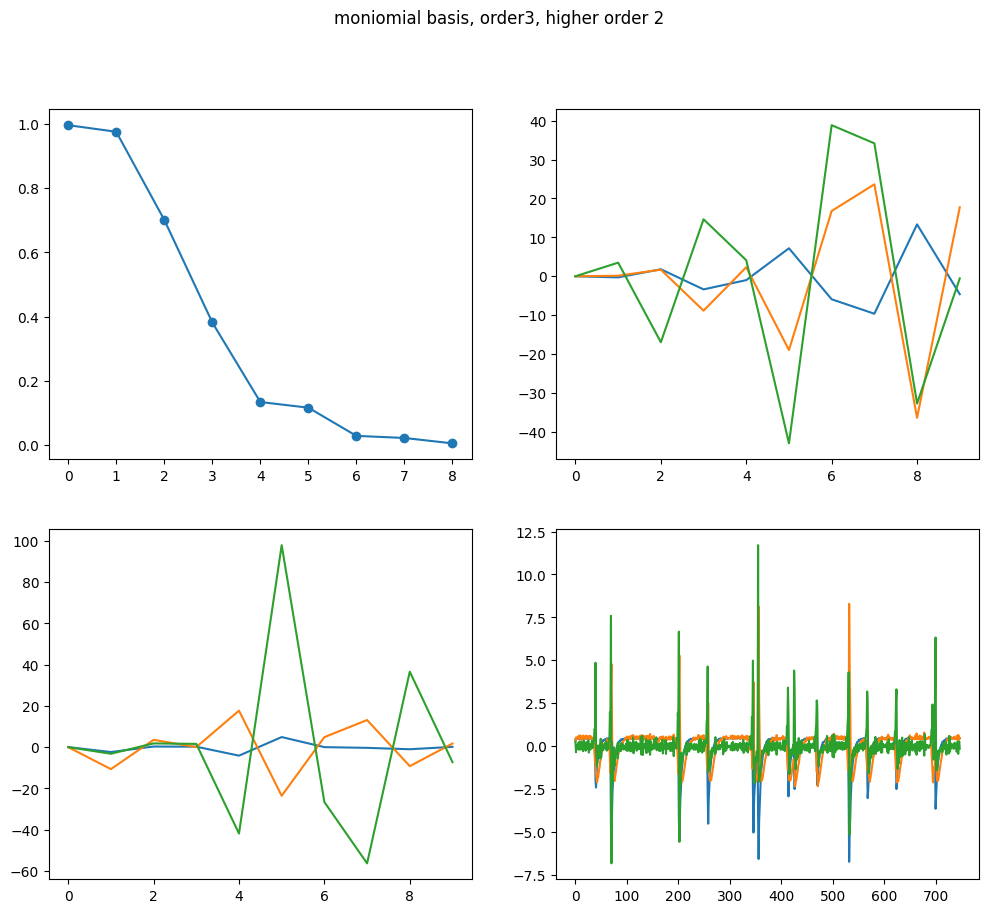

In [30]:
# make 2 by 2 plots, the first one is singular values, the second one is the first left singular vector
# the thrid one is the projection and the 4th one is the 3D scatter of the projection

fig, ax = plt.subplots(2,2, figsize=(12, 10))
ax[0,0].plot(vamp_model.singular_values[:],'o-')
ax[0,1].plot(vamp_model.singular_vectors_left[:,:3])
ax[1,0].plot(vamp_model.singular_vectors_right[:,:3])
ax[1,1].plot(projection)
# add figure title
fig.suptitle("moniomial basis, order " + str(degree) + ", higher order " + str(higher_order))
# plt.close()

In [31]:
vamp_model.singular_vectors_right.shape

(10, 3)

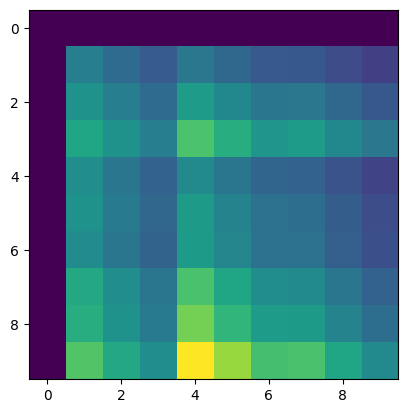

In [32]:
plt.figure()
plt.imshow(vamp_model.cov_0t)
plt.show()

<Axes: >

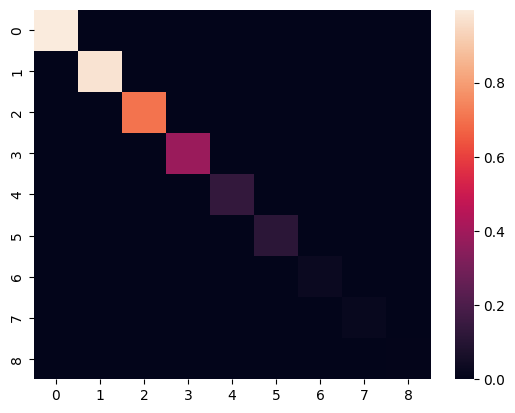

In [63]:
sns.heatmap(vamp_model.koopman_matrix)

<Axes: >

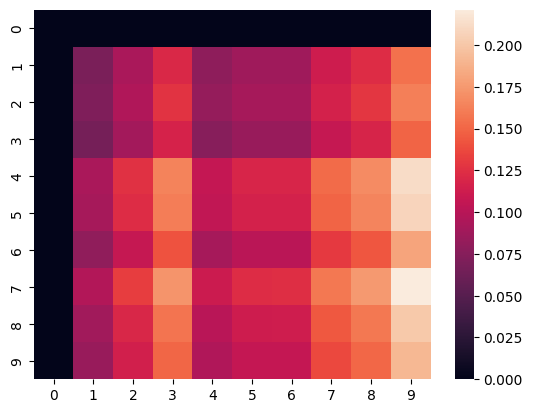

In [70]:
sns.heatmap(vamp_model.cov_00 @ vamp_model.cov_0t.T)

In [33]:
projection.shape

(748, 3)

In [34]:
traj.shape

(750,)

In [35]:
from ipywidgets import VBox

In [36]:
projection.shape

(748, 3)

In [49]:
fig = fpl.Figure()#cameras="3d", controller_types="orbit")
fig.renderer.blend_mode = "weighted_plus"

fig2 = fpl.Figure(shape=(2, 1), controller_ids="sync", names=[["left"], ["right"]])

# sg = fig[0, 0].add_scatter(projection[:, :3], sizes=5, alpha=0.5)

scatter_data = np.column_stack([projection[:, 0], projection_right[:, 0]])
sg = fig[0, 0].add_scatter(scatter_data, sizes=5, alpha=0.5)
fig[0, 0].axes.intersection = (0, 0, 0)
lg = fig2[0, 0].add_line(traj[1:-1], cmap="viridis", cmap_transform=projection[:, 0])
# proj_g = fig2[1, 0].add_line_collection(projection[:, :3].T, cmap="tab10")

lg2 = fig2[1, 0].add_line(traj[1:-1], cmap="viridis", cmap_transform=projection_right[:, 0])

# fig[0, 0].axes.colors = (
#     proj_g[0].colors[0],
#     proj_g[1].colors[0],
#     proj_g[2].colors[0]
# )

sel = lg.add_linear_selector()
sel2 = lg2.add_linear_selector()

@sel.add_event_handler("selection")
def update_time(ev):
    if isinstance(ev, int):
        ix = ev
    else:
        ix = ev.get_selected_index()
    sg.sizes = 5
    sg.colors = (1, 1, 1, 0.5)
    
    sg.colors[ix] = "r"
    sg.sizes[ix] = 10
    sel2.selection = sel.selection

@sg.add_event_handler("double_click")
def update_time_from_sg(ev):
    ix = ev.pick_info["vertex_index"]
    sel.selection = lg.data[ix, 0]  # set x val from line data

VBox([fig.show(), fig2.show(maintain_aspect=False)])

RFBOutputContext()

RFBOutputContext()

In [ ]:
lg.add_linear_selector

In [44]:
vamp_model.operator_inverse

array([[  1.0464347 ,   0.        ,   0.        ,   0.        ,
          0.        ,   0.        ,   0.        ,   0.        ,
          0.        ,   0.        ,   0.        ,   0.        ,
          0.        ,   0.        ,   0.        ,   0.        ],
       [  0.        ,   1.29774957,   0.        ,   0.        ,
          0.        ,   0.        ,   0.        ,   0.        ,
          0.        ,   0.        ,   0.        ,   0.        ,
          0.        ,   0.        ,   0.        ,   0.        ],
       [  0.        ,   0.        ,   1.73757318,   0.        ,
          0.        ,   0.        ,   0.        ,   0.        ,
          0.        ,   0.        ,   0.        ,   0.        ,
          0.        ,   0.        ,   0.        ,   0.        ],
       [  0.        ,   0.        ,   0.        ,   2.36736683,
          0.        ,   0.        ,   0.        ,   0.        ,
          0.        ,   0.        ,   0.        ,   0.        ,
          0.        ,   0.        ,  